# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024170228          # <-- your full roll number
NAME = "MIHIR KHANNA"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170228   Name: MIHIR KHANNA   Fingerprint: 57932C57   Tickets: 15

Ticket_ID                                                                                           Ticket_Text
      T01                                  Printer is not working while uploading the file. Can you check this?
      T02                                       I was locked out of the VPN during the lab. Can you check this?
      T03                                                                         The LMS says 'Not Submitted'.
      T04                               WiFi was working yesterday since yesterday. I have tried several times!
      T05                         I can't open the email after the latest update. It works on another computer.
      T06                                     Printer keeps asking for login on my laptop. It worked yesterday.
      T07                                   I am unable to use the VPN on my laptop. I don't know what changed.
      T08           

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [7]:
import pandas as pd

processed = [process_ticket(text) for text in df["Ticket_Text"]]

rows = []

for i, p in enumerate(processed):

    rows.append({
        "Ticket": df.iloc[i]["Ticket_ID"],
        "Sentences": len(p["sentences"]),
        "Tokens": len(p["tokens"]),
        "Punctuation": len(p["punct"]),
        "Stopwords": len(p["stops"]),
        "Unique Tokens": len(set(p["tokens"])),
        "Final Tokens": len(p["final"])
    })

result = pd.DataFrame(rows)

total = {
    "Ticket": "TOTAL",
    "Sentences": result["Sentences"].sum(),
    "Tokens": result["Tokens"].sum(),
    "Punctuation": result["Punctuation"].sum(),
    "Stopwords": result["Stopwords"].sum(),
    "Unique Tokens": result["Unique Tokens"].sum(),
    "Final Tokens": result["Final Tokens"].sum()
}

result = pd.concat(
    [result, pd.DataFrame([total])],
    ignore_index=True
)

print(result.to_string(index=False))

Ticket  Sentences  Tokens  Punctuation  Stopwords  Unique Tokens  Final Tokens
   T01          2      14            2          7             14             5
   T02          2      16            2         10             15             4
   T03          1       7            2          1              7             4
   T04          2      13            2          3             12             8
   T05          2      17            2          6             15             9
   T06          2      13            2          4             12             7
   T07          2      18            2          9             16             7
   T08          2      11            2          4             11             5
   T09          1       7            2          2              7             3
   T10          2      19            2          9             16             8
   T11          1       9            1          3              9             5
   T12          2      10            2          3   

In [8]:
p = processed[0]

print("ACTUAL TOKENS:")
print(p["tokens"])

print("\nPUNCTUATION TOKENS:")
print(p["punct"])

print("\nSTOPWORDS:")
print(p["stops"])

print("\nFINAL TOKENS:")
print(p["final"])

ACTUAL TOKENS:
['printer', 'is', 'not', 'working', 'while', 'uploading', 'the', 'file', '.', 'can', 'you', 'check', 'this', '?']

PUNCTUATION TOKENS:
['.', '?']

STOPWORDS:
['is', 'not', 'while', 'the', 'can', 'you', 'this']

FINAL TOKENS:
['printer', 'working', 'uploading', 'file', 'check']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens are not real standalone words, such as n't, 's, and ca. They come from splitting contractions during tokenization; for example, can't may become ca + n't, and isn't becomes is + n't.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [10]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re


long_word_pattern = r'\b[A-Za-z]{6,}\b'

number_pattern = r'\b(?:0[xX][0-9A-Fa-f]+|\d+(?:,\d{3})*(?:\.\d+)+|\d+(?:,\d{3})*)\b'

capitalized_pattern = r'\b[A-Z][A-Za-z]*\b'


vowel_pattern = r'\b[AEIOUaeiou][A-Za-z]*\b'



for ticket_id, ticket in zip(df["Ticket_ID"], df["Ticket_Text"]):

    print("\n" + "=" * 60)
    print(ticket_id)
    print(ticket)

    long_words = re.findall(long_word_pattern, ticket)

    numbers = re.findall(number_pattern, ticket)

    capitalized_words = re.findall(capitalized_pattern, ticket)

    vowel_words = re.findall(vowel_pattern, ticket)

    print("\nWords longer than 5 letters:")
    print(long_words)

    print("\nNumbers:")
    print(numbers)

    print("\nCapitalized words:")
    print(capitalized_words)

    print("\nWords beginning with a vowel:")
    print(vowel_words)



email_pattern = r'\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b'

url_pattern = r'https?://[^\s]+|www\.[^\s]+'

phone_pattern = (
    r'(?:'
    r'\+91[-\s]?\d{5}[-\s]?\d{5}'
    r'|'
    r'0\d{3}[-\s]\d{3}[-\s]\d{4}'
    r')'
)



print("\n\n" + "#" * 70)
print("REPLACEMENT RESULTS")
print("#" * 70)

for ticket_id, ticket in zip(df["Ticket_ID"], df["Ticket_Text"]):

    replaced = ticket

    replaced = re.sub(email_pattern, "<EMAIL>", replaced)
    replaced = re.sub(url_pattern, "<URL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)

    print("\n" + ticket_id)
    print("Original :", ticket)
    print("Replaced :", replaced)

print("\n\n" + "#" * 70)
print("TEST_LINES")
print("#" * 70)

for line in TEST_LINES:

    print("\nOriginal:")
    print(line)

    print("\nLong words:")
    print(re.findall(long_word_pattern, line))

    print("\nNumbers:")
    print(re.findall(number_pattern, line))

    print("\nCapitalized words:")
    print(re.findall(capitalized_pattern, line))

    print("\nVowel words:")
    print(re.findall(vowel_pattern, line))

    replaced = line
    replaced = re.sub(email_pattern, "<EMAIL>", replaced)
    replaced = re.sub(url_pattern, "<URL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)

    print("\nAfter replacement:")
    print(replaced)


T01
Printer is not working while uploading the file. Can you check this?

Words longer than 5 letters:
['Printer', 'working', 'uploading']

Numbers:
[]

Capitalized words:
['Printer', 'Can']

Words beginning with a vowel:
['is', 'uploading']

T02
I was locked out of the VPN during the lab. Can you check this?

Words longer than 5 letters:
['locked', 'during']

Numbers:
[]

Capitalized words:
['I', 'VPN', 'Can']

Words beginning with a vowel:
['I', 'out', 'of']

T03
The LMS says 'Not Submitted'.

Words longer than 5 letters:
['Submitted']

Numbers:
[]

Capitalized words:
['The', 'LMS', 'Not', 'Submitted']

Words beginning with a vowel:
[]

T04
WiFi was working yesterday since yesterday. I have tried several times!

Words longer than 5 letters:
['working', 'yesterday', 'yesterday', 'several']

Numbers:
[]

Capitalized words:
['WiFi', 'I']

Words beginning with a vowel:
['I']

T05
I can't open the email after the latest update. It works on another computer.

Words longer than 5 letters:


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 27 capitalized words are capitalized only because they occur at the beginning of a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [11]:
from nltk.tokenize import RegexpTokenizer, word_tokenize
import re

pattern = r"""
https?://[^\s]+
|www\.[^\s]+
|[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}
|\+91[-\s]?\d{5}[-\s]?\d{5}
|0\d{3}[-\s]\d{3}[-\s]\d{4}
|\d+(?:\.\d+)+
|\d+\.\d+
|[A-Za-z]+(?:'[A-Za-z]+)?
|[A-Za-z]+(?:-[A-Za-z]+)+
|[A-Za-z]+
|[.,!?;:()]
"""

tokenizer = RegexpTokenizer(pattern, flags=re.VERBOSE)


def my_tokenize(text):
    return tokenizer.tokenize(text)

In [13]:
for line in TEST_LINES:

    print("\nOriginal:")
    print(line)

    print("\nMy tokenizer:")
    print(my_tokenize(line))

    print("\nword_tokenize:")
    print(word_tokenize(line))


Original:
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.

My tokenizer:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

word_tokenize:
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original:
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

My tokenizer:
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', 'done', ';', 'fee', 'Rs', ',', '.']

word_tokenize:
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original:
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

My t

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*Number of tickets tokenized differently:7

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [14]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()

# Remove common suffixes such as -ing, -ed and -ly
regexp_stemmer = RegexpStemmer(r'ing$|ed$|ly$', min=4)

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):

    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('N'):
        return 'n'
    elif tag.startswith('R'):
        return 'r'
    else:
        return 'n'

unique_final_tokens = set()

for p in processed:
    unique_final_tokens.update(p["final"])

unique_final_tokens = sorted(unique_final_tokens)

print("Number of unique final tokens:", len(unique_final_tokens))

tagged_tokens = pos_tag(unique_final_tokens)

comparison = []

for word, tag in tagged_tokens:

    porter_result = porter.stem(word)

    lancaster_result = lancaster.stem(word)

    regexp_result = regexp_stemmer.stem(word)

    wordnet_pos = get_wordnet_pos(tag)
    lemma_result = lemmatizer.lemmatize(word, wordnet_pos)

    # Keep only words where results differ
    if len({
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    }) > 1:

        comparison.append({
            "Word": word,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regexp": regexp_result,
            "Lemmatizer": lemma_result
        })

stem_df = pd.DataFrame(comparison)

print(stem_df.to_string(index=False))



Number of unique final tokens: 63
     Word  Porter Lancaster   Regexp Lemmatizer
  another   anoth     anoth  another    another
     call    call       cal     call       call
   campus   campu      camp   campus     campus
  changed   chang     chang    chang     change
 computer  comput    comput computer   computer
  crashes   crash     crash  crashes      crash
     file    file       fil     file       file
  getting     get       get     gett        get
   jammed     jam       jam     jamm        jam
    keeps    keep      keep    keeps       keep
   latest  latest    latest   latest       late
      lms      lm       lms      lms         lm
   logged     log       log     logg     logged
   mobile   mobil      mobl   mobile     mobile
   occurs   occur       occ   occurs      occur
     open    open        op     open       open
  opening    open        op     open    opening
   portal  portal      port   portal     portal
  printer printer     print  printer    printer
     s

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
Over-stemming: “another” → “anoth” (Lancaster), where too much of the word is removed. Under-stemming: “latest” → “latest” (Porter), where the related form is not reduced to “late”.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [15]:
from collections import Counter
from nltk.util import bigrams
import matplotlib.pyplot as plt
import numpy as np

# S1: all tokens
S1 = []

# S2: tokens without punctuation
S2 = []

# S3: final tokens
S3 = []

for p in processed:

    S1.extend(p["tokens"])

    S2.extend([
        token for token in p["tokens"]
        if token not in p["punct"]
    ])

    S3.extend(p["final"])


# S4: S3 after Porter stemming
S4 = [porter.stem(token) for token in S3]

def get_statistics(tokens):

    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))

    if total_tokens > 0:
        ttr = unique_tokens / total_tokens
    else:
        ttr = 0

    return total_tokens, unique_tokens, ttr


stats = []

for name, tokens in [
    ("S1", S1),
    ("S2", S2),
    ("S3", S3),
    ("S4", S4)
]:

    total, unique, ttr = get_statistics(tokens)

    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": ttr
    })

stats_df = pd.DataFrame(stats)

print(stats_df.to_string(index=False))



Corpus  Total Tokens  Unique Tokens      TTR
    S1           197             97 0.492386
    S2           168             91 0.541667
    S3            92             63 0.684783
    S4            92             58 0.630435


In [16]:
s1_counts = Counter(S1)

print("Top 10 words of S1:")
for word, frequency in s1_counts.most_common(10):
    print(word, ":", frequency)

Top 10 words of S1:
. : 20
the : 15
i : 9
is : 5
yesterday : 5
? : 4
n't : 4
it : 4
on : 4
to : 4


In [17]:
s3_counts = Counter(S3)

print("\nTop 10 words of S3:")
for word, frequency in s3_counts.most_common(10):
    print(word, ":", frequency)


Top 10 words of S3:
yesterday : 5
n't : 4
printer : 3
working : 3
wifi : 3
another : 3
use : 3
file : 2
check : 2
vpn : 2


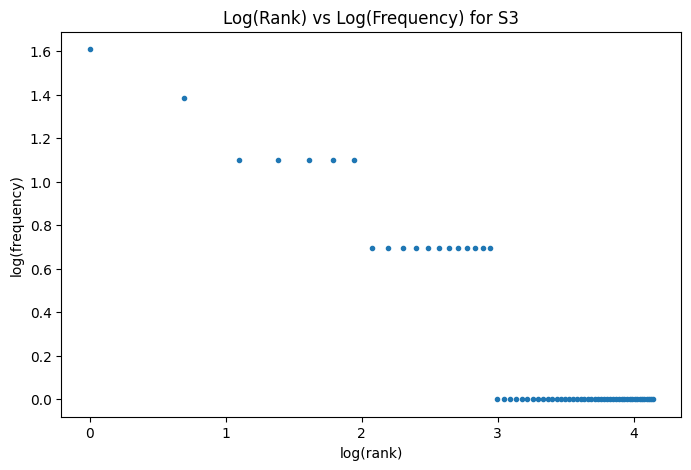

In [18]:
frequencies = sorted(
    Counter(S3).values(),
    reverse=True
)

ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    np.log(ranks),
    np.log(frequencies),
    marker='o',
    linestyle='none',
    markersize=3
)

plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")

plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*TTR changes from S1 to S4 because stemming combines different forms of the same word into common stems, reducing the number of unique tokens while the total tokens remain the same.

